# ML1_Pipeline + Model

This notebook is organized into several steps:
1. How to load and prepare the data  
2. How to properly use `train_test_split`  
3. How to create preprocessing pipelines  
4. How to implement and evaluate a regression model

## Objective
Predict the planting year of trees using Machine Learning best practices.

## 1. Importing Necessary Libraries and Loading Data

We use several essential libraries:
- pandas and numpy: for data manipulation  
- sklearn: for Machine Learning  
- matplotlib: for visualization

In [61]:
# %conda install  seaborn matplotlib  -y
# %pip install --upgrade seaborn
# Necessary libraries.
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error, root_mean_squared_error

We load the data from the pickle file containing our cleaned dataset.

In [45]:
# Load the data from the pickle file.
df = pd.read_pickle('arbres_clean_Alexia.pkl')

In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 31670 entries, 0 to 31669
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   sous_categorie_desc    31670 non-null  str    
 1   code_parent_desc       31670 non-null  str    
 2   adr_secteur            31670 non-null  str    
 3   genre_bota             31670 non-null  str    
 4   espece                 31670 non-null  str    
 5   variete                31670 non-null  str    
 6   stadededeveloppement   31670 non-null  str    
 7   remarques              31670 non-null  str    
 8   anneedeplantation      29526 non-null  float64
 9   raisondeplantation     31670 non-null  str    
 10  traitementchenilles    31670 non-null  str    
 11  identifiantplu         31670 non-null  str    
 12  typeimplantationplu    31670 non-null  str    
 13  intituleprotectionplu  31670 non-null  str    
 14  collectivite           31670 non-null  str    
 15  stationmetro 

## 2. Preparing Data for ML and Train-Test Split

First important step: remove NaNs from the target, then separate our explanatory variables (features) from our target variable.

Second step: Train-Test split

In [47]:
# Remove rows without planting year
# We can use the *dropna()* method to delete rows where 'planting_year' is NaN

df.dropna(subset=['anneedeplantation'], inplace=True)

# Train/test split
# We can use scikit-learn's *train_test_split()* method to split the data into training and testing sets
from sklearn.model_selection import train_test_split

X = df.drop('anneedeplantation', axis=1)
y = df['anneedeplantation']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

/tmp/ipykernel_86586/2533644267.py:4: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['anneedeplantation'], inplace=True)


## [Optional] How can we fill missing values without using a pipeline?

In [19]:
# Fill missing values with the most frequent value for each affected column

## [Optional] Creating New Features (Feature Engineering)

In [20]:
# Code

## 3. Creating Preprocessing Pipelines

Pipelines are essential to:
1. Automate transformations  
2. Prevent data leakage  
3. Ensure consistency between train and test sets

### 3.1 Data Preparation & Base Model

We prepare the data using a `scikit-learn` pipeline:  
- **OneHotEncoder** for categorical variables  
- **StandardScaler** for numerical variables  
- **LinearRegression** as the base model

In [48]:
# Which variables are categorical and which are numerical?  

categorical_variables = X.select_dtypes(include = ['str']).columns.tolist()
numerical_variables = X.select_dtypes(include = ['number']).columns.tolist()
print(categorical_variables,numerical_variables)
for col in categorical_variables:
    print(col, X[col].nunique())



['sous_categorie_desc', 'code_parent_desc', 'adr_secteur', 'genre_bota', 'espece', 'variete', 'stadededeveloppement', 'remarques', 'raisondeplantation', 'traitementchenilles', 'identifiantplu', 'typeimplantationplu', 'intituleprotectionplu', 'collectivite', 'stationmetro', 'hauteurarbre', 'portarbre', 'structure', 'forme', 'typenature'] ['latitude', 'longitude']
sous_categorie_desc 4
code_parent_desc 270
adr_secteur 11
genre_bota 62
espece 104
variete 24
stadededeveloppement 4
remarques 18
raisondeplantation 4
traitementchenilles 4
identifiantplu 5
typeimplantationplu 5
intituleprotectionplu 4
collectivite 3
stationmetro 3
hauteurarbre 4
portarbre 6
structure 5
forme 4
typenature 6



# What is OneHotEncoder?  

> OneHotEncoder is a method used in preprocessing to convert categorical variables into a format that can be provided to machine learning algorithms to improve predictions. It creates binary columns for each category in the variable.

# Does it also handle missing values in the categorical variables?
>
> No, OneHotEncoder does not handle missing values by default. You need to handle missing values separately, for example by using SimpleImputer to fill in missing values before applying OneHotEncoder.

# What is StandardScaler?

> StandardScaler is a method used to standardize numerical features by removing the mean and scaling to unit variance. This ensures that each feature contributes equally to the model and helps improve the performance of many machine learning algorithms.



In [49]:
# [OPTIONAL] Quick check for missing values  
# Should be 0 for all columns in both train and test sets

# Number of missing values per column:
df.isnull().sum()





sous_categorie_desc      0
code_parent_desc         0
adr_secteur              0
genre_bota               0
espece                   0
variete                  0
stadededeveloppement     0
remarques                0
anneedeplantation        0
raisondeplantation       0
traitementchenilles      0
identifiantplu           0
typeimplantationplu      0
intituleprotectionplu    0
collectivite             0
stationmetro             0
hauteurarbre             0
portarbre                0
structure                0
forme                    0
typenature               0
latitude                 0
longitude                0
dtype: int64

In [50]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder())
])

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [56]:
preprocessor = ColumnTransformer([
    ('cat', categorical_pipeline, categorical_variables),
    ('num', numerical_pipeline, numerical_variables)
])

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

X_train_transformed
X_test_transformed

    

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 129932 stored elements and shape (5906, 552)>

## 4. Evaluation with LinearRegression and multiple metrics:
- **MAE** (Mean Absolute Error)  
- Others?

This simple model will serve as a baseline for comparison with more advanced models (such as decision trees or random forests).

In [62]:
# We can use scikit-learn's 'mean_absolute_error' to evaluate the performance of the regression model

model = LinearRegression()

model.fit(X_train_transformed, y_train)

y_pred_train = model.predict(X_train_transformed)
y_pred_test = model.predict(X_test_transformed)


print('train')
mae = mean_absolute_error(y_train,y_pred_train)
print(f"MAE: {mae:.2f}")

r2 = r2_score(y_train, y_pred_train)
print(f"R²: {r2:.3f}")

rmse = root_mean_squared_error(y_train,y_pred_train)
print(f"RMSE: {rmse:.2f}")


print('test')
mae = mean_absolute_error(y_test, y_pred_test)
print(f"MAE: {mae:.2f}")

r2 = r2_score(y_test,y_pred_test)
print(f"R²: {r2:.3f}")

rmse = root_mean_squared_error(y_test, y_pred_test)
print(f"RMSE: {rmse:.2f}")

train
MAE: 6.34
R²: 0.755
RMSE: 9.01
test
MAE: 6.46
R²: 0.749
RMSE: 9.02


## 5. Visualization of Predictions

Let's visualize the relationship between the actual and predicted values:

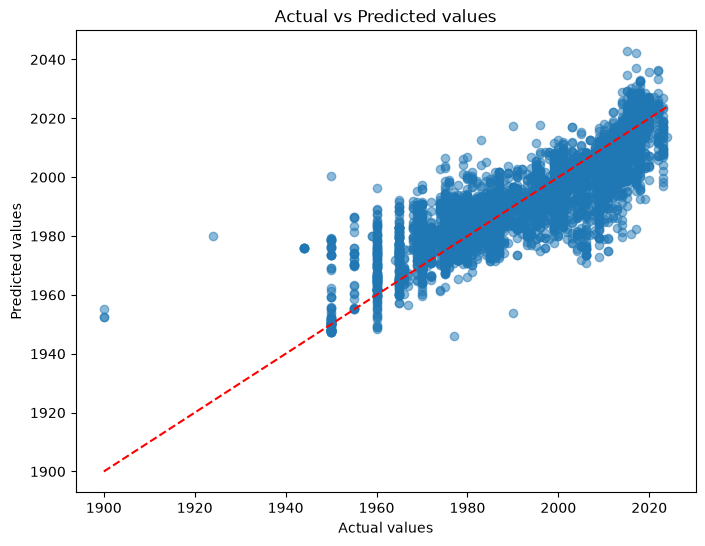

In [64]:
# Code

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_test, alpha=0.5)

# Línea de predicción perfecta
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()], 'r--')

plt.xlabel('Actual values')
plt.ylabel('Predicted values')
plt.title('Actual vs Predicted values')

plt.show()

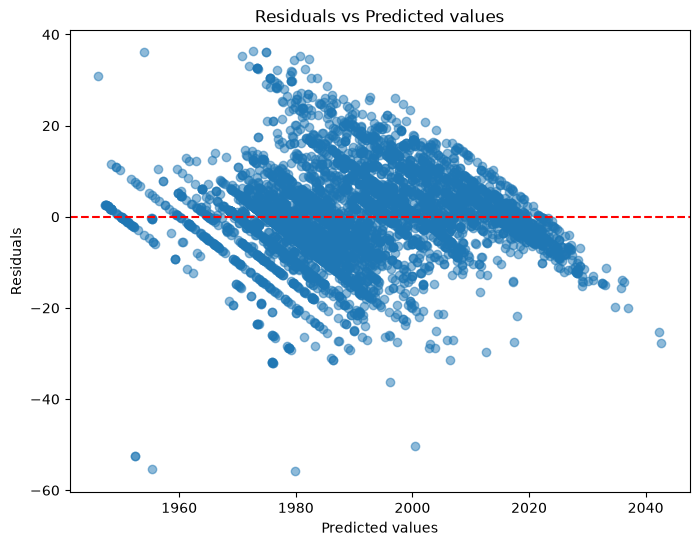

In [65]:
residuals = y_test - y_pred_test

plt.figure(figsize=(8, 6))

plt.scatter(y_pred_test, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted values')

plt.show()

## Conclusion